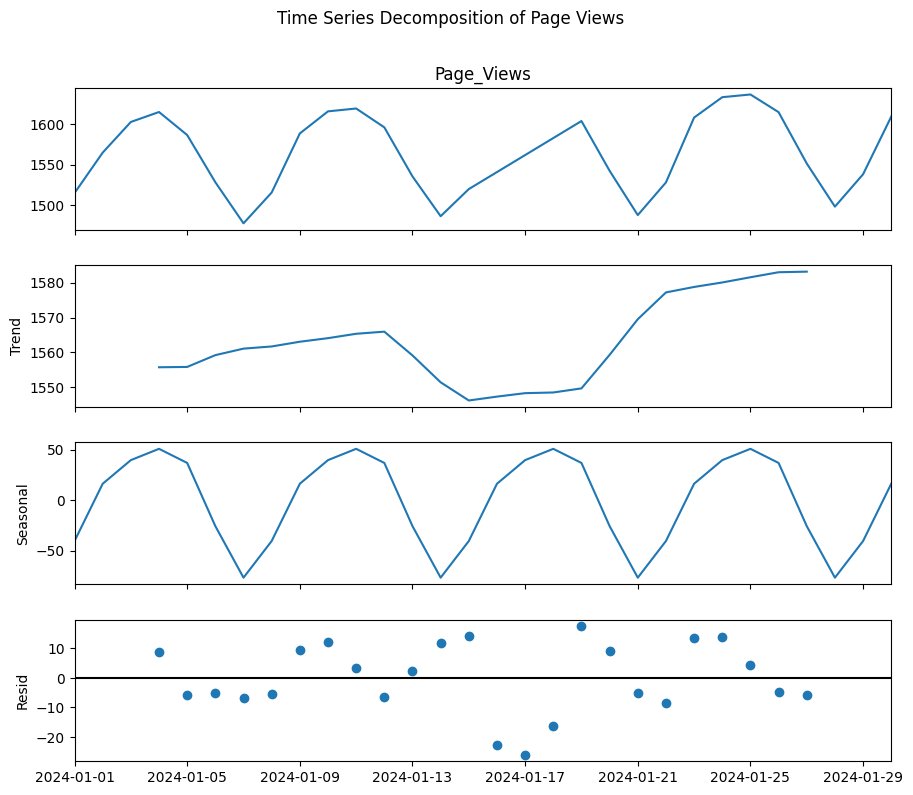

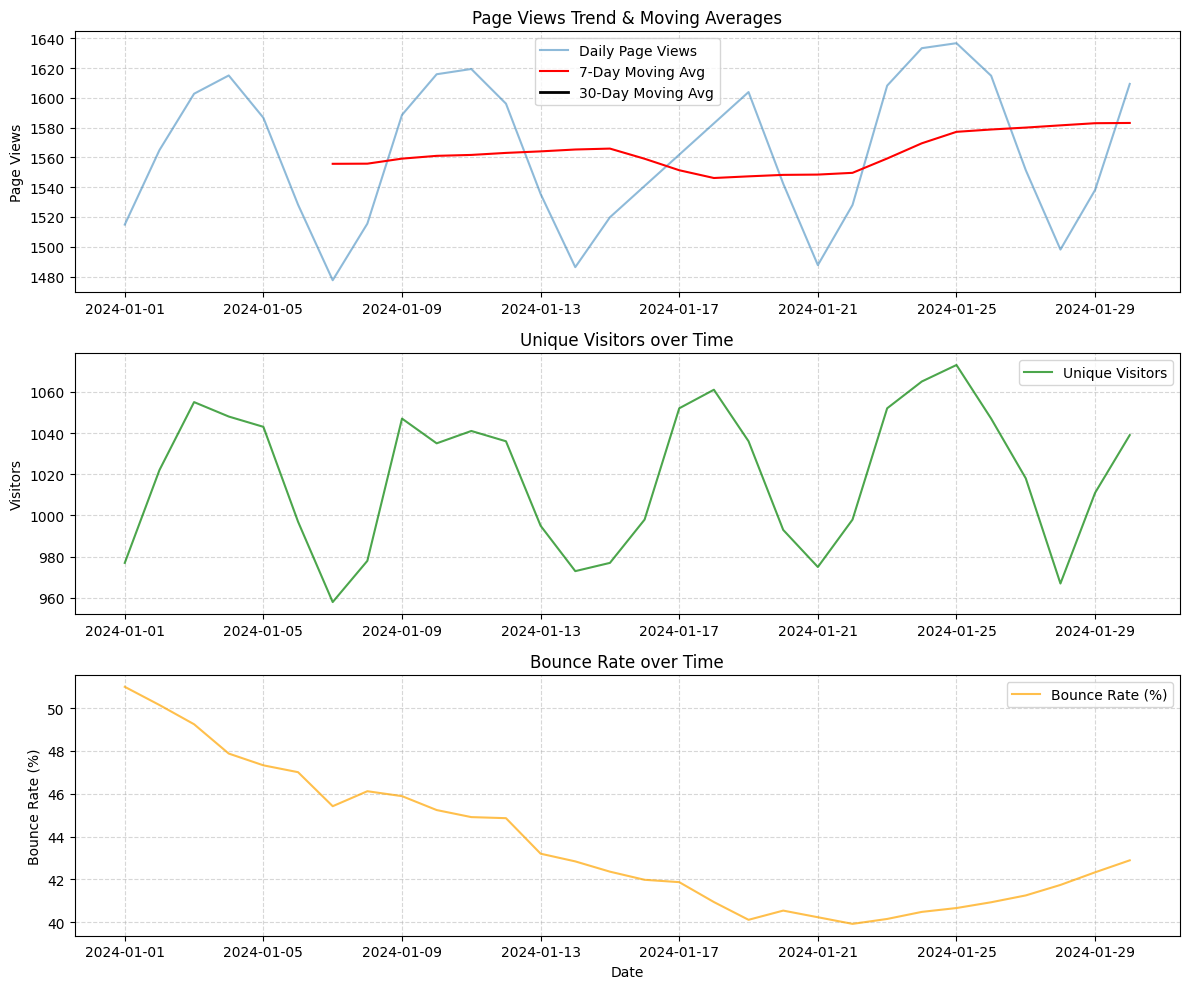

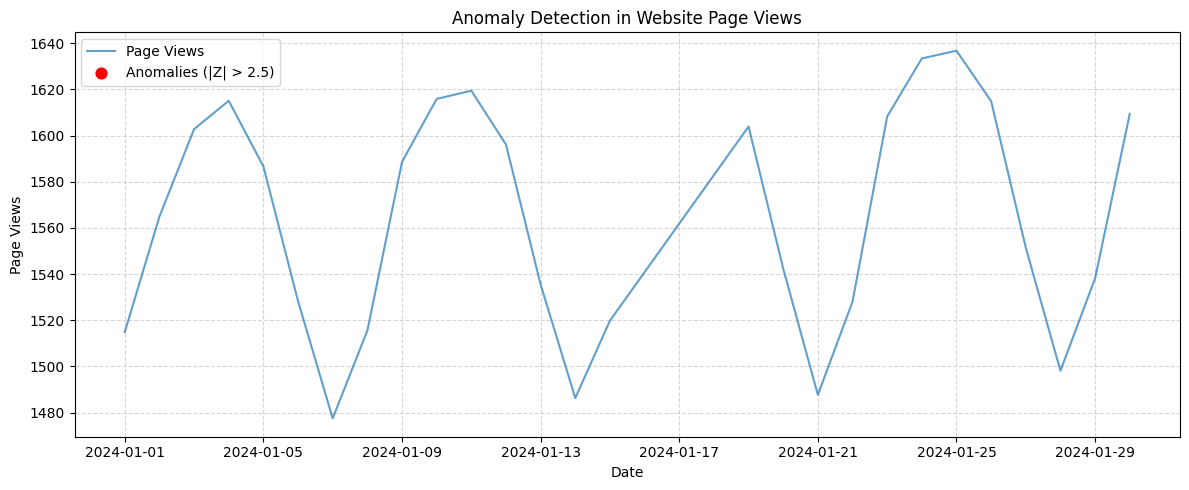

Detected Anomalies:
Empty DataFrame
Columns: [Page_Views, Page_Views_Z]
Index: []


In [6]:
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose

# ==========================================
# 1. LOAD AND CLEAN DATA
# ==========================================
# Load dataset, parse Date column, and set as index
data = pd.read_csv(
    r"C:\Users\nafee\OneDrive\Documents\time_series.csv", parse_dates=["Date"], index_col="Date"
)

# Handle missing values using linear interpolation (Required before decomposition)
data = data.interpolate(method="time")
data = data.ffill().bfill()  # Handle any remaining boundary NaNs

# ==========================================
# 2. TIME SERIES DECOMPOSITION
# ==========================================
# Decompose Page_Views (period=7 accounts for weekly seasonality in daily data)
decomposition = seasonal_decompose(
    data["Page_Views"], model="additive", period=7
)
fig_decomp = decomposition.plot()
fig_decomp.set_size_inches(10, 8)
fig_decomp.suptitle(
    "Time Series Decomposition of Page Views", fontsize=12, y=1.02
)
plt.show()

# ==========================================
# 3. VISUALIZATION & MOVING AVERAGES
# ==========================================
plt.figure(figsize=(12, 10))

# Subplot 1: Page Views & Moving Average
plt.subplot(3, 1, 1)
plt.plot(data.index, data["Page_Views"], label="Daily Page Views", alpha=0.5)
plt.plot(
    data.index,
    data["Page_Views"].rolling(window=7).mean(),
    label="7-Day Moving Avg",
    color="red",
    linewidth=1.5,
)
plt.plot(
    data.index,
    data["Page_Views"].rolling(window=30).mean(),
    label="30-Day Moving Avg",
    color="black",
    linewidth=2,
)
plt.title("Page Views Trend & Moving Averages")
plt.ylabel("Page Views")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Unique Visitors
plt.subplot(3, 1, 2)
plt.plot(
    data.index,
    data["Unique_Visitors"],
    label="Unique Visitors",
    color="green",
    alpha=0.7,
)
plt.title("Unique Visitors over Time")
plt.ylabel("Visitors")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Subplot 3: Bounce Rate
plt.subplot(3, 1, 3)
plt.plot(
    data.index,
    data["Bounce_Rate"],
    label="Bounce Rate (%)",
    color="orange",
    alpha=0.7,
)
plt.title("Bounce Rate over Time")
plt.xlabel("Date")
plt.ylabel("Bounce Rate (%)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ==========================================
# 4. ANOMALY DETECTION (Z-SCORE METHOD)
# ==========================================
# Calculate Z-scores for Page_Views
data["Page_Views_Z"] = (
    data["Page_Views"] - data["Page_Views"].mean()
) / data["Page_Views"].std()

# Threshold of 2.5 standard deviations (captures significant anomalies)
threshold = 2.5
anomalies = data[data["Page_Views_Z"].abs() > threshold]

# Plot Page Views with Anomalies
plt.figure(figsize=(12, 5))
plt.plot(data.index, data["Page_Views"], label="Page Views", alpha=0.7)
plt.scatter(
    anomalies.index,
    anomalies["Page_Views"],
    color="red",
    s=60,
    label=f"Anomalies (|Z| > {threshold})",
    zorder=5,
)
plt.title("Anomaly Detection in Website Page Views")
plt.xlabel("Date")
plt.ylabel("Page Views")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Print detected anomaly dates and values
print("Detected Anomalies:")
print(anomalies[["Page_Views", "Page_Views_Z"]])